In [3]:
import pandas as pd
import numpy as np

# Set seed for reproducibility
np.random.seed(42)

# Number of records
n_records = 1000

# Generating dummy data for 7 columns
loan_ids = [f'LP{str(i).zfill(4)}' for i in range(1, n_records + 1)]
ages = np.random.randint(21, 65, size=n_records)
incomes = np.random.randint(20000, 150000, size=n_records)
loan_amounts = np.random.randint(5000, 100000, size=n_records)
credit_scores = np.random.randint(300, 850, size=n_records)
years_at_job = np.random.randint(0, 25, size=n_records)

# Simple rule-based approval to make the dummy data semi-realistic
# Approved if high credit score or low debt-to-income ratio
loan_status = []
for i in range(n_records):
    score_factor = credit_scores[i] > 600
    income_factor = (loan_amounts[i] / incomes[i]) < 0.4
    if score_factor and income_factor:
        status = 'Approved'
    elif score_factor or income_factor:
        status = np.random.choice(['Approved', 'Rejected'], p=[0.6, 0.4])
    else:
        status = np.random.choice(['Approved', 'Rejected'], p=[0.1, 0.9])
    loan_status.append(status)

# Create DataFrame
df_loans = pd.DataFrame({
    'Loan_ID': loan_ids,
    'Age': ages,
    'Income': incomes,
    'Loan_Amount': loan_amounts,
    'Credit_Score': credit_scores,
    'Years_at_Job': years_at_job,
    'Loan_Status': loan_status
})

# Display shape and first few rows
print(f"Dataset shape: {df_loans.shape}")
display(df_loans.head())

Dataset shape: (1000, 7)


,Loan_ID,Age,Income,Loan_Amount,Credit_Score,Years_at_Job,Loan_Status
0,LP0001,59,24018,52837,417,20,Rejected
1,LP0002,49,31302,16536,460,4,Rejected
2,LP0003,35,87506,33541,700,5,Approved
3,LP0004,63,61157,84083,497,16,Rejected
4,LP0005,28,74917,56027,559,0,Rejected


In [2]:
# Show class distribution to confirm loan approvals and rejections
display(df_loans['Loan_Status'].value_counts().to_frame())

,count
Loan_Status,
Rejected,528
Approved,472


### Train a Logistic Regression Model
We will prepare the data by encoding the categorical target (`Loan_Status`), scaling the numerical features, splitting the data into train and test sets, and finally fitting a `LogisticRegression` model.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Prepare features and target
# Exclude 'Loan_ID' as it's just an identifier
X = df_loans.drop(columns=['Loan_ID', 'Loan_Status'])
y = df_loans['Loan_Status'].apply(lambda x: 1 if x == 'Approved' else 0) # 1 for Approved, 0 for Rejected

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train the Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

In [5]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7300

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.73      0.78      0.75       106
    Approved       0.73      0.67      0.70        94

    accuracy                           0.73       200
   macro avg       0.73      0.73      0.73       200
weighted avg       0.73      0.73      0.73       200

Confusion Matrix:
[[83 23]
 [31 63]]


### Bias-Variance Analysis via Learning Curves
We will use `learning_curve` from `sklearn.model_selection` to analyze the model's bias and variance.
- **High Bias (Underfitting)**: Both training and validation scores are low and close to each other.
- **High Variance (Overfitting)**: High training score but significantly lower validation score (a large gap).

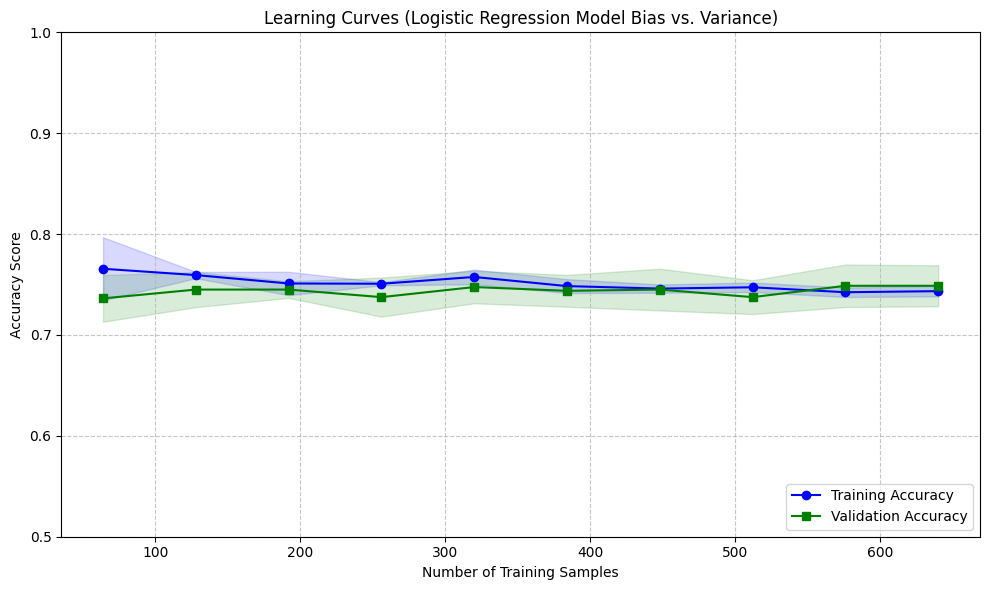

In [6]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Calculate learning curve
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    random_state=42
)

# Calculate mean and standard deviation for training and validation scores
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
validation_mean = np.mean(validation_scores, axis=1)
validation_std = np.std(validation_scores, axis=1)

# Plot the learning curves
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, label='Training Accuracy', color='blue', marker='o')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, validation_mean, label='Validation Accuracy', color='green', marker='s')
plt.fill_between(train_sizes, validation_mean - validation_std, validation_mean + validation_std, alpha=0.15, color='green')

plt.title('Learning Curves (Logistic Regression Model Bias vs. Variance)')
plt.xlabel('Number of Training Samples')
plt.ylabel('Accuracy Score')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

### Loan Status Distribution
We will visualize the proportion of 'Approved' vs. 'Rejected' loans in our dataset using a pie chart.

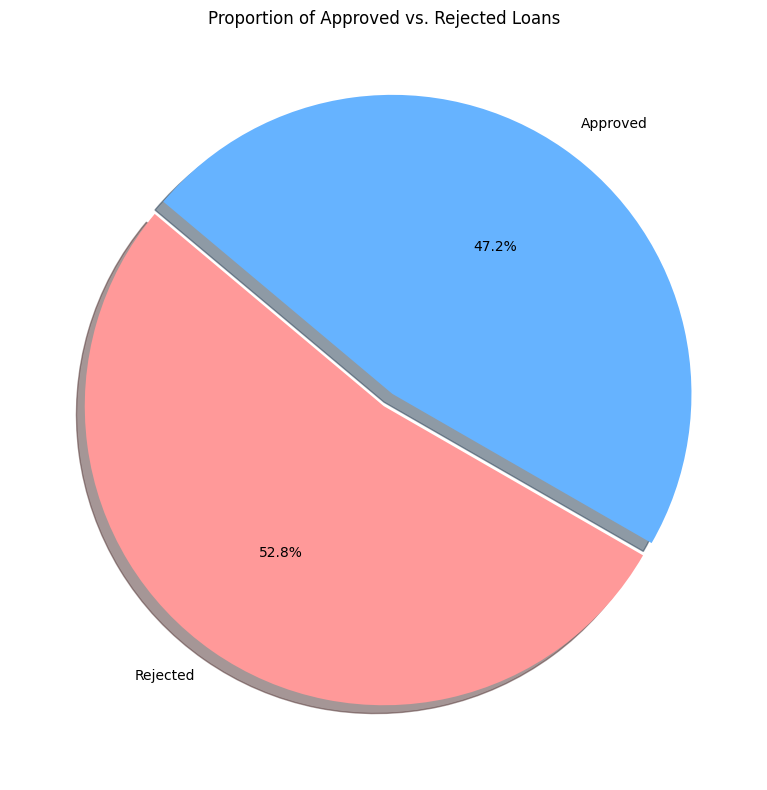

In [7]:
import matplotlib.pyplot as plt

# Get counts of loan status
status_counts = df_loans['Loan_Status'].value_counts()

# Plot pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#ff9999', '#66b3ff'],
    explode=(0, 0.05),
    shadow=True
)
plt.title('Proportion of Approved vs. Rejected Loans')
plt.tight_layout()
plt.show()

### Interactive Loan Prediction Tool
Use the input fields below to test the trained model on custom loan application scenarios.

In [8]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd

# Create interactive input widgets
age_widget = widgets.IntSlider(value=35, min=21, max=100, step=1, description='Age:')
income_widget = widgets.IntText(value=75000, description='Income ($):')
loan_amount_widget = widgets.IntText(value=30000, description='Loan Amt ($):')
credit_score_widget = widgets.IntSlider(value=650, min=300, max=850, step=10, description='Credit Score:')
years_at_job_widget = widgets.IntSlider(value=5, min=0, max=50, step=1, description='Job Years:')

predict_button = widgets.Button(
    description='Predict Loan Status',
    button_style='success',
    tooltip='Click to predict loan status with custom values',
    icon='check'
)

output_area = widgets.Output()

def make_prediction(b):
    with output_area:
        clear_output()

        # Prepare input data matching model features: Age, Income, Loan_Amount, Credit_Score, Years_at_Job
        custom_data = pd.DataFrame({
            'Age': [age_widget.value],
            'Income': [income_widget.value],
            'Loan_Amount': [loan_amount_widget.value],
            'Credit_Score': [credit_score_widget.value],
            'Years_at_Job': [years_at_job_widget.value]
        })

        # Standardize features using the previously fitted scaler
        custom_data_scaled = scaler.transform(custom_data)

        # Get model prediction and probability
        prediction = model.predict(custom_data_scaled)[0]
        probabilities = model.predict_proba(custom_data_scaled)[0]

        # Format result display
        status_label = 'Approved' if prediction == 1 else 'Rejected'
        confidence = probabilities[prediction] * 100

        color = '#2ca02c' if prediction == 1 else '#d62728'

        print("-" * 40)
        print("Input Summary:")
        for col in custom_data.columns:
            print(f"  {col}: {custom_data.loc[0, col]:,}")
        print("-" * 40)
        display(widgets.HTML(f"""
            <div style="padding:15px; border-radius:5px; background-color:#f9f9f9; border-left:8px solid {color};">
                <h3 style="margin:0; color:{color};">Prediction: {status_label}</h3>
                <p style="margin:5px 0 0 0;">Model Confidence: <strong>{confidence:.2f}%</strong></p>
            </div>
        """))

predict_button.on_click(make_prediction)

# Group and display widgets
input_container = widgets.VBox([
    widgets.HTML("<h4>Enter Loan Details:</h4>"),
    age_widget,
    income_widget,
    loan_amount_widget,
    credit_score_widget,
    years_at_job_widget,
    widgets.HTML("<br>"),
    predict_button,
    output_area
])

display(input_container)